# Trading-bot development notebook (phase-1 research)

Interactive playground mirroring the CLI pipeline: load pooled data → discretize →
backtest single rules → test-set evaluation → plots.

Open this notebook from the project root (kernel cwd = repo root).
Run order matters: cells depend on previous cells' objects (like the legacy `experiments/main*.ipynb`).

CLI equivalents (outside the notebook):
- `.venv/bin/python -m src.miner --direction long`  (env `MINER_FAST=1` for smoke)
- `.venv/bin/python main.py --quick`               — NSGA-II smoke
- `.venv/bin/python -m src.report --direction long`— test evaluation

In [1]:
import os, sys, re, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def _find_root(start=None):
    here = os.path.abspath(start or os.getcwd())
    for cand in (here, os.path.dirname(here), os.path.join(os.path.dirname(here), os.path.basename(here))):
        if os.path.exists(os.path.join(cand, 'main.py')) and os.path.exists(os.path.join(cand, 'src')):
            return cand
    raise FileNotFoundError('project root (main.py + src/) not found')

ROOT = _find_root()
os.chdir(ROOT)                     # all relative paths (dataset/, results/) resolve to the root
sys.path.insert(0, ROOT)           # import config / src from the project root

from config import load_config
from src.data.loader import assemble
from src.core.discretizer import FeatureDiscretizer
from src.core.backtest import CapitalManagedTradeSimulator
from src.initialization import build_pool
from src.features.builder import FeatureBuilder
import main as main_module

CFG = load_config()
print('ROOT:', ROOT)
print('symbols:', CFG.symbols, '| tf:', CFG.timeframe, '| boundary:', CFG.train_test_split)

ROOT: /home/mhseddighi/Projects/trading-bot
symbols: ['BTCUSDT', 'ETHUSDT', 'SOLUSDT', 'XRPUSDT', 'DOGEUSDT'] | tf: 5m | boundary: 2026-08-21


## 1. Final feature files (normalized, train/test)

In [2]:
feature_dir = CFG.feature_cache_dir
train = pd.read_parquet(os.path.join(feature_dir, 'train.parquet'))
test = pd.read_parquet(os.path.join(feature_dir, 'test.parquet'))
feature_cols = [c for c in train.columns
                if not c.startswith(('candle_', 'label_')) and c not in ('datetime', 'symbol')]
print(f'features: {len(feature_cols)} | train rows: {len(train):,} | test rows: {len(test):,}')
train.head(3)

features: 73 | train rows: 172,440 | test rows: 88,205


,datetime,candle_open,candle_high,candle_low,candle_close,candle_volume,label_open_next,label_close_288,label_max_288,label_min_288,...,h_range_pos_30d,h_dd_30d,btc_logret_12,btc_logret_48,btc_logret_288,btc_realized_vol_288,btc_volatility_ratio_48_288,symbol_relative_return_288,symbol_btc_corr_288,symbol
0,2026-04-22 06:00:00,77994.92,78007.37,77920.00,77959.84,56.77906,77959.84,78127.30,79472.82,77453.43,...,0.963401,-0.003817,0.006127,0.021639,0.028699,0.026166,0.443968,0.0,1.0,BTCUSDT
1,2026-04-22 06:05:00,77959.84,77974.65,77913.23,77941.99,164.76158,77941.99,78229.25,79472.82,77453.43,...,0.962074,-0.004045,0.005061,0.020682,0.028306,0.026168,0.444549,0.0,1.0,BTCUSDT
2,2026-04-22 06:10:00,77941.99,78015.16,77919.31,77950.76,58.89278,77950.76,78196.63,79472.82,77453.43,...,0.962726,-0.003933,0.005172,0.015655,0.028130,0.026168,0.404885,0.0,1.0,BTCUSDT


## 6. End-to-end runs from the notebook (optional)

In [3]:
# pinned direction for this notebook (parent dev.ipynb takes it from CFG)
import main

OPT = main.main(direction='short')



🎯 Pooled NSGA-II | phase=research | SHORT | symbols=5
📦 Loading pooled data (all symbols)...
   📦 Final feature files already present in dataset/features
   ✂️  split=train: 172,440 rows (boundary 2026-08-21)
   Features: 73 | Samples: 172,440
   Conditions: 302
📚 Loaded 5716 rules from results/pool/short/all_symbols.csv
🔬 Clusters: 3 | Min: 2, Max: 3044, Std: 1354
   Pool rules: 5716
   Chromosome: 45 genes (9 slots × 5)

🚀 Starting pooled optimization (200 gens, pop 200)


📊 Initialization Stats:
   Pool rules used: 1404 unique (1800 total)
 gen  |  evals  |  nds  |        REXP        |        RWP         |        ROB         |   time 
    1 |     200 |     5 |   -0.3847 | 0.0450 |  -17.1596 | 5.5358 |    0.3027 | 4.8741 |    0.0s
    2 |     400 |     7 |  -0.7551 | -0.1051 | -23.4246 | -1.4211 |    0.1364 | 3.1595 |    4.2s
    3 |     600 |     8 |  -0.7551 | -0.2128 | -27.2300 | -5.2026 |   -0.1480 | 2.4207 |    4.3s
    4 |     800 |    13 |  -0.8614 | -0.3153 | -27.2300 | -7.9

## 7. Evaluate final population as WHOLE rulesets (train + test), choose & save

Each strategy = decoded NSGA chromosome = multi-rule ruleset (3..6 rules), TP/SL/cap genes per rule (cap ∈ 1–3%).

In [4]:
import numpy as np, json, datetime, os
from src.core.backtest import CapitalManagedTradeSimulator
from src.core.discretizer import FeatureDiscretizer
from src.data.loader import assemble

direction = OPT['cfg'].direction
dec = OPT['decoder']
X_pop, F_pop = OPT['result'].pop.get("X"), OPT['result'].pop.get("F")

# one self-contained setup: discretizer fitted on the FULL train split,
# sims for both splits, real-price arrays for trade records.
feats_tr, fc_tr, labels_tr_v, meta_tr = assemble(train)
disc = FeatureDiscretizer(); feat_info, _ = disc.fit(feats_tr)
dc = np.array([i['dont_care'] for i in feat_info])
dt_tr = disc.transform(feats_tr)

feats_te, fc_te, labels_te, meta_te = assemble(test)
dt_te = disc.transform(feats_te)

train_sim = CapitalManagedTradeSimulator(dt_tr, fc_tr, labels_tr_v, meta_tr, direction, dc)
test_sim  = CapitalManagedTradeSimulator(dt_te, fc_te, labels_te, meta_te, direction, dc)

price_tr = train.sort_values(['datetime', 'symbol']).reset_index(drop=True)['candle_close'].to_numpy(float)
price_te = test.sort_values(['datetime', 'symbol']).reset_index(drop=True)['candle_close'].to_numpy(float)

def metrics_pack(m):
    return dict(pnl=m['total_return_pct'], dd=m['max_drawdown_pct'], trades=m['executed_trades'],
                wr=m['win_rate'], pf=m['profit_factor'],
                pnls=m['trade_pnls'], entry_idx=m['trade_entry_idx'], exit_idx=m['trade_exit_idx'],
                notional=m['trade_notional'])

strategies = []
for i, x in enumerate(X_pop):
    rules = dec.decode(np.asarray(x, dtype=int)).get('rules_set', [])
    if len(rules) < dec.min_rules:
        continue
    strategies.append(dict(idx=i, rules=rules, train=metrics_pack(train_sim.simulate_rule_set(rules)),
                           test=metrics_pack(test_sim.simulate_rule_set(rules))))
# drop non-positive strategies entirely (train or test pnl <= 0)
# strategies = [s for s in strategies if s['train']['pnl'] > 0 and s['test']['pnl'] > 0]

# rank like report.py: worst split decides (min of train/test pnl)
strategies.sort(key=lambda s: -min(s['train']['pnl'], s['test']['pnl']))
def _nd_sort(items):
    n = len(items)
    rank = [0] * n
    def dominates(a, b):
        return all(x <= y for x, y in zip(a, b)) and any(x < y for x, y in zip(a, b))
    remaining = set(range(n))
    cur = 0
    while remaining:
        front = []
        for i in list(remaining):
            if not any(j != i and dominates(items[j], items[i]) for j in remaining):
                front.append(i)
        for i in front:
            rank[i] = cur
        remaining -= set(front)
        cur += 1
    return rank

# NDS: train pnl, test pnl maximized; train dd, test dd minimized
nds_perf = [(-s['train']['pnl'], -s['test']['pnl'], s['train']['dd'], s['test']['dd']) for s in strategies]
nds_rank = _nd_sort(nds_perf)
for s, nr in zip(strategies, nds_rank):
    s['nds'] = nr
strategies.sort(key=lambda s: (s['nds'], -min(s['train']['pnl'], s['test']['pnl'])))

print(f'population: {len(X_pop)} | valid multi-rule strategies: {len(strategies)}')

fmt = '{:>4} {:>7} {:>9} {:>8} {:>7} {:>7} {:>7} | {:>9} {:>8} {:>7} {:>7} {:>7} {:>4}'
print(fmt.format(
    '#', 'n_rules', 'trPnL%', 'trDD%', 'trWR', 'trTrd', 'trPF',
    'tePnL%', 'teDD%', 'teWR', 'teTrd', 'tePF', 'NDS'
))
print('-' * 105)

for nr, s in enumerate(strategies, start=1):
    t, e = s['train'], s['test']

    print(fmt.format(
        nr,
        len(s['rules']),
        f"{t['pnl']:.2f}",
        f"{t['dd']:.2f}",
        f"{t['wr']:.1f}",
        t['trades'],
        f"{t['pf']:.2f}",
        f"{e['pnl']:.2f}",
        f"{e['dd']:.2f}",
        f"{e['wr']:.1f}",
        e['trades'],
        f"{e['pf']:.2f}",
        s['nds'],
    ))


population: 200 | valid multi-rule strategies: 200
   # n_rules    trPnL%    trDD%    trWR   trTrd    trPF |    tePnL%    teDD%    teWR   teTrd    tePF  NDS
---------------------------------------------------------------------------------------------------------
   1       6     71.41     1.65    74.2    1685    5.90 |     -3.01     8.20    32.5     726    0.82    0
   2       8     87.09     1.65    76.2    2043    6.33 |     -3.27     8.54    32.0     797    0.81    0
   3       8     83.03     1.64    75.1    2123    6.39 |     -3.27     8.90    34.4     857    0.82    0
   4       7     79.20     1.65    74.8    1792    6.13 |     -3.29     8.45    32.6     760    0.81    0
   5       8     84.55     1.63    75.5    2182    6.52 |     -3.35     8.60    33.6     860    0.81    0
   6       8     88.18     1.65    75.7    2038    6.25 |     -3.42     8.76    32.0     797    0.81    0
   7       7     80.61     1.61    75.1    2147    6.45 |     -3.49     8.77    33.6     858    0.80 

## 8. Per-rule breakdown of the top strategies (train vs test)

In [5]:
# Store ranked strategies straight by their table index — no extra
# selection rules. Point STORE_BY_INDEX at the rows of the table above.
STORE_BY_INDEX = [0]   # by default store only the first ranked solution (NDS front 1); other table rows are shown anyway
out_dir = os.path.join('results', direction)
os.makedirs(out_dir, exist_ok=True)
ts = datetime.datetime.now().strftime('%Y%m%d_%H%M%S')
stored = []
for si, r_i in enumerate(STORE_BY_INDEX):
    if r_i >= len(strategies):
        print(f"skipped row {r_i}: not enough positive-pnl strategies ({len(strategies)} available)")
        continue
    s = strategies[r_i]
    doc = dict(index=r_i, direction=direction, rank=si + 1, pop_idx=s['idx'], timestamp=ts,
               train={k: s['train'][k] for k in ('pnl', 'dd', 'trades', 'wr', 'pf')},
               test={k: s['test'][k] for k in ('pnl', 'dd', 'trades', 'wr', 'pf')},
               strategy=dict(direction=direction, rules_set=[
                   dict(rule_id=rl['rule_id'], conditions=list(rl['conditions']), tp=rl['tp'],
                        sl=rl['sl'], capital_pct=rl['capital_pct']) for rl in s['rules']]))
    fname = os.path.join(out_dir, f'strategy_{si+1:02d}_{ts}.json')
    json.dump(doc, open(fname, 'w'), indent=2, default=str)
    stored.append((fname, s))
    print(f"stored: {fname}  train pnl={s['train']['pnl']:.2f}% dd={s['train']['dd']:.2f}%  "
          f"test pnl={s['test']['pnl']:.2f}% dd={s['test']['dd']:.2f}%")


stored: results/short/strategy_01_20261023_194055.json  train pnl=71.41% dd=1.65%  test pnl=-3.01% dd=8.20%


In [6]:
for r, s in enumerate(strategies[:5]):
    print(f"\n──── strategy #{r} (pop idx {s['idx']}) — {len(s['rules'])} rules ────")
    for k, rule in enumerate(s['rules']):
        mt = train_sim.simulate_rule_set([rule])
        me = test_sim.simulate_rule_set([rule])
        print(f"  rule{k+1} id={rule['rule_id']} tp={rule['tp']} sl={rule['sl']} cap={rule['capital_pct']}% "
              f"train pnl={mt['total_return_pct']:6.2f}% dd={mt['max_drawdown_pct']:5.2f}% trd={mt['executed_trades']:5d} | "
              f"test pnl={me['total_return_pct']:6.2f}% dd={me['max_drawdown_pct']:5.2f}% trd={me['executed_trades']:5d}")
        print(f"        {' AND '.join(rule['conditions'])}")
    print(f"  WHOLE: train pnl={s['train']['pnl']:.2f}% dd={s['train']['dd']:.2f}% | test pnl={s['test']['pnl']:.2f}% dd={s['test']['dd']:.2f}%")


──── strategy #0 (pop idx 180) — 6 rules ────
  rule1 id=311 tp=3.0 sl=2.0 cap=2.8% train pnl=  5.77% dd= 0.35% trd=   99 | test pnl= -1.37% dd= 1.72% trd=   43
        [logret_3] IS Low AND [realized_vol_288] IS High AND [obv_zscore_288] IS Low AND [macro_efficiency_720] IS High AND [btc_logret_288] IS Low
  rule2 id=1807 tp=6.5 sl=2.3 cap=1.0% train pnl= 24.75% dd= 1.87% trd=  959 | test pnl= -8.85% dd= 8.85% trd=  497
        [realized_vol_288] IS High AND [obv_zscore_288] IS Low AND [macro_volatility_ratio_288_1440] IS High AND [h_momz_24h] IS Low AND [btc_realized_vol_288] IS High
  rule3 id=2127 tp=3.5 sl=1.2 cap=3.0% train pnl=  6.74% dd= 2.13% trd=  223 | test pnl=  0.00% dd=100.00% trd=    0
        [realized_vol_288] IS Low AND [return_skew_288] IS High AND [h_momz_30d] IS High AND [btc_realized_vol_288] IS Low
  rule4 id=2479 tp=4.5 sl=2.0 cap=2.8% train pnl= 10.36% dd= 1.33% trd=  379 | test pnl=  5.78% dd= 1.22% trd=  108
        [realized_vol_288] IS Low AND [macro_chann

## 7b. Fold-robustness diagnostics (per-rule, per-fold)
Rebuilds the SAME chronological folds the optimizer's ROB objective uses and shows, for the top of the
population table, which rules actually earn in which periods. A rule that contributes pnl in only 1–2
folds is a regime bet — treat suspicion accordingly. This is a *diagnostic*; it must not replace the
out-of-search validation gate.

In [7]:
import numpy as np, pandas as pd

FOLDN = 12                                  # keep in sync with cfg.n_folds
rows = train.sort_values(['datetime', 'symbol']).reset_index(drop=True)
n = len(rows)
fold_size = n // FOLDN
folds = [(i * fold_size, n if i == FOLDN - 1 else (i + 1) * fold_size) for i in range(FOLDN)]


def fold_sims():
    sims = []
    for s, e in folds:
        feats, fc, labs, mt = assemble(rows.iloc[s:e].copy())
        dt = disc.transform(feats)
        sims.append(CapitalManagedTradeSimulator(dt, fc, labs, mt, direction, dc))
    return sims


for r, s in enumerate(strategies[:5]):
    fsims = fold_sims()
    print(f"\n──── strategy #{r} (pop idx {s['idx']}) — {len(s['rules'])} rules ────")
    table = []
    for k, rule in enumerate(s['rules']):
        fl_ret, fl_trd = [], []
        for sim_f in fsims:
            m = sim_f.simulate_rule_set([dict(rule)])
            fl_ret.append(float(m['total_return_pct']) if m['executed_trades'] > 0 else 0.0)
            fl_trd.append(int(m['executed_trades']))
        m_tr = train_sim.simulate_rule_set([dict(rule)])
        m_te = test_sim.simulate_rule_set([dict(rule)])
        table.append(dict(rule=f"r{k+1}(id {rule['rule_id']})",
                          **{f"f{i}{chr(10)}ret/trd" + chr(10): "" for i in ()},
                          **{f"f{i}": f"{ret:+5.1f}/{trd:3d}" for i, (ret, trd) in enumerate(zip(fl_ret, fl_trd))},
                          pos_folds=f"{sum(v > 0 for v in fl_ret)}/{FOLDN}",
                          whole_tr=f"{m_tr['total_return_pct']:+6.1f}%",
                          whole_te=f"{m_te['total_return_pct']:+6.1f}%"))
    print(pd.DataFrame(table).to_string(index=False))



──── strategy #0 (pop idx 180) — 6 rules ────
       rule        f0        f1        f2        f3        f4        f5        f6        f7        f8        f9       f10       f11 pos_folds whole_tr whole_te
 r1(id 311)  +0.0/  0  +0.0/  0  +0.1/  3  +0.0/  0  +1.3/ 28  +3.1/ 45  +0.8/ 15  +0.1/  2  +0.3/  5  -0.1/  1  +0.0/  0  +0.0/  0      6/12    +5.8%    -1.4%
r2(id 1807)  -0.6/ 68  -1.0/ 70  +0.0/  0  -0.0/  1 +21.4/410  +2.5/110  +0.8/240  +1.2/ 59  +0.0/  0  +0.0/  0  +0.0/  0  +0.0/  0      4/12   +24.7%    -8.9%
r3(id 2127)  +3.0/ 40  -0.7/ 34  +0.0/  0  +0.0/  0  +0.0/  0  +0.0/  0  +0.0/  0  -1.4/ 68  +0.0/  0  +4.0/ 45  +2.5/ 42  -0.1/  1      3/12    +6.7%    +0.0%
r4(id 2479)  -0.7/ 36  +1.1/ 22  +0.0/  0  +5.2/ 98  +2.7/ 36  -0.1/  2  -0.1/ 36  +0.0/  0  +0.0/  0  +2.2/ 41  -0.8/ 59  +2.3/ 72      5/12   +10.4%    +5.8%
r5(id 3676)  +2.4/ 34  +0.0/  0  +0.0/  0  +0.0/  0  +0.0/  0  +0.0/  0  +4.0/ 34  +0.0/  0  +0.2/ 13  -0.1/  2  +0.0/  0  +0.3/ 34      4/12    +6.8%   

## 7b. Fold-robustness diagnostics (per-rule, per-fold)
Rebuilds the SAME chronological folds the optimizer's ROB objective uses and shows, for the top of the
population table, which rules actually earn in which periods. A rule that contributes pnl in only 1–2
folds is a regime bet — treat suspicion accordingly. This is a *diagnostic*; it must not replace the
out-of-search validation gate.

In [8]:
import numpy as np, pandas as pd

FOLDN = 12                                  # keep in sync with cfg.n_folds
FOLD_MIN_TPD = max(2, 0)                    # fold floor trace (fitness uses max(2, min_trades//n_folds))

rows = train.sort_values(['datetime', 'symbol']).reset_index(drop=True)
n = len(rows)
fold_size = n // FOLDN
folds = [(i * fold_size, n if i == FOLDN - 1 else (i + 1) * fold_size) for i in range(FOLDN)]


def fold_sims():
    sims = []
    for s, e in folds:
        feats, fc, labs, mt = assemble(rows.iloc[s:e].copy())
        dt = disc.transform(feats)
        sims.append((CapitalManagedTradeSimulator(dt, fc, labs, mt, direction, dc), s, e))
    return sims


for r, s in enumerate(strategies[:5]):
    fsims = fold_sims()
    print(f"\n──── strategy #{r} (pop idx {s['idx']}) — {len(s['rules'])} rules ────")
    table = []
    for k, rule in enumerate(s['rules']):
        fl_ret, fl_trd = [], []
        for sim_f, lo, hi in fsims:
            m = sim_f.simulate_rule_set([{**rule}])
            fl_ret.append(float(m['total_return_pct']) if m['executed_trades'] > 0 else 0.0)
            fl_trd.append(int(m['executed_trades']))
        # per-trade contribution of this rule WITHIN its folds (rule attribution)
        contrib = []
        m_full = train_sim.simulate_rule_set([rule])
        rid_pos = list(s['rules']).index(rule)
        row = dict(rule=f"r{k+1}(id {rule['rule_id']})",
                   **{f"f{i}": f"{ret:+5.1f}/{trd:3d}" for i, (ret, trd) in enumerate(zip(fl_ret, fl_trd))},
                   **{"pct_pos_fold": f"{sum(v > 0 for v in fl_ret)}/{FOLDN}",
                      "whole_tr": f"{m_full['total_return_pct']:+6.1f}%",
                      "whole_te": f"{test_sim.simulate_rule_set([{**rule}])['total_return_pct']:+6.1f}%"})
        table.append(row)
    print(pd.DataFrame(table).to_string(index=False))



──── strategy #0 (pop idx 180) — 6 rules ────
       rule        f0        f1        f2        f3        f4        f5        f6        f7        f8        f9       f10       f11 pct_pos_fold whole_tr whole_te
 r1(id 311)  +0.0/  0  +0.0/  0  +0.1/  3  +0.0/  0  +1.3/ 28  +3.1/ 45  +0.8/ 15  +0.1/  2  +0.3/  5  -0.1/  1  +0.0/  0  +0.0/  0         6/12    +5.8%    -1.4%
r2(id 1807)  -0.6/ 68  -1.0/ 70  +0.0/  0  -0.0/  1 +21.4/410  +2.5/110  +0.8/240  +1.2/ 59  +0.0/  0  +0.0/  0  +0.0/  0  +0.0/  0         4/12   +24.7%    -8.9%
r3(id 2127)  +3.0/ 40  -0.7/ 34  +0.0/  0  +0.0/  0  +0.0/  0  +0.0/  0  +0.0/  0  -1.4/ 68  +0.0/  0  +4.0/ 45  +2.5/ 42  -0.1/  1         3/12    +6.7%    +0.0%
r4(id 2479)  -0.7/ 36  +1.1/ 22  +0.0/  0  +5.2/ 98  +2.7/ 36  -0.1/  2  -0.1/ 36  +0.0/  0  +0.0/  0  +2.2/ 41  -0.8/ 59  +2.3/ 72         5/12   +10.4%    +5.8%
r5(id 3676)  +2.4/ 34  +0.0/  0  +0.0/  0  +0.0/  0  +0.0/  0  +0.0/  0  +4.0/ 34  +0.0/  0  +0.2/ 13  -0.1/  2  +0.0/  0  +0.3/ 34       

## 9. Choose & save strategies (JSON incl. every trade with REAL prices)

Edit `SAVE` to pick the rows from the table in section 7.

In [9]:
def trade_records(sim, m, labels_, meta_, price_arr):
    """Per-trade detail with real prices for one split.
    Entry = next-open (label_open_next). Exit row = the entry symbol's release row
    (same symbol, after the max-hold window), so dates/prices always belong to
    the traded symbol. Exit price entry-price * (1 + gross ret), gross ret
    reconstructed from the fee-inclusive net pnl."""
    fe = sim.round_trip_fee_rate
    sym_names = np.asarray(meta_['symbol_names'])
    sym_codes = sim.symbol_codes
    n_dt = len(meta_['datetime'])
    if len(m['pnls']) == 0:
        return []
    _last_idx = {}
    for pos, sc in enumerate(sym_codes):
        _last_idx[sc] = pos
    rec, equity = [], sim.initial_capital
    for j in range(len(m['pnls'])):
        ei, pnl, notional = int(m['entry_idx'][j]), float(m['pnls'][j]), float(m['notional'][j])
        if notional <= 0:
            continue
        xi = int(sim.release_index[ei])                        # exit row of the SAME symbol
        if xi >= n_dt:                                          # trade still open at data end ->
            xi = int(_last_idx[sym_codes[ei]])                  # use that symbol's final bar
        gross_ret = pnl / notional + fe
        entry_px = float(labels_['label_open_next'][ei])
        equity += pnl
        rec.append(dict(symbol=str(sym_names[sym_codes[ei]]),
                        entry_dt=str(meta_['datetime'][ei]), exit_dt=str(meta_['datetime'][xi]),
                        entry_price=round(entry_px, 6),
                        exit_price=round(entry_px * (1.0 + gross_ret), 6),
                        close_at_exit=round(float(price_arr[xi]), 6),
                        gross_ret_pct=round(gross_ret * 100.0, 4), pnl_usd=round(pnl, 4),
                        notional=round(notional, 2), equity_after=round(equity, 2)))
    return sorted(rec, key=lambda t: t['exit_dt'])


SAVE = [0, 1, 2]          # <- choose table rows to store
out_dir = os.path.join('results', direction)
os.makedirs(out_dir, exist_ok=True)
ts = datetime.datetime.now().strftime('%Y%m%d_%H%M%S')
saved = []
for si, r_i in enumerate(SAVE):
    s = strategies[r_i]
    doc = dict(direction=direction, rank=si + 1, pop_idx=s['idx'], timestamp=ts,
               train={k: s['train'][k] for k in ('pnl', 'dd', 'trades', 'wr', 'pf')},
               test={k: s['test'][k] for k in ('pnl', 'dd', 'trades', 'wr', 'pf')},
               test_calmar=s['test']['pnl'] / max(s['test']['dd'], 1e-3),
               trades=trade_records(train_sim, s['train'], labels_tr_v, meta_tr, price_tr),
               trades_test=trade_records(test_sim, s['test'], labels_te, meta_te, price_te),
               strategy=dict(direction=direction, rules_set=[
                   dict(rule_id=rl['rule_id'], conditions=list(rl['conditions']), tp=rl['tp'], sl=rl['sl'],
                        capital_pct=rl['capital_pct']) for rl in s['rules']]))
    fname = os.path.join(out_dir, f'strategy_{si+1:02d}_{ts}.json')
    json.dump(doc, open(fname, 'w'), indent=2, default=str)
    saved.append((fname, s))
    print(f"saved: {fname}  train pnl={s['train']['pnl']:.2f}% dd={s['train']['dd']:.2f}%  "
          f"test pnl={s['test']['pnl']:.2f}% dd={s['test']['dd']:.2f}%")


saved: results/short/strategy_01_20261023_194111.json  train pnl=71.41% dd=1.65%  test pnl=-3.01% dd=8.20%
saved: results/short/strategy_02_20261023_194111.json  train pnl=87.09% dd=1.65%  test pnl=-3.27% dd=8.54%
saved: results/short/strategy_03_20261023_194111.json  train pnl=83.03% dd=1.64%  test pnl=-3.27% dd=8.90%


## 10. Real-price comparison (train vs test) for a saved strategy

Candle-price levels per symbol per split, next to the strategy's $ profit / drawdown, so the two splits can be compared in real terms.

strategy file: results/short/strategy_01_20261023_194111.json

TRAIN: pnl final  +71.41% | max dd  1.65% | final equity $ 1,714.09 | trades 1685
TEST : pnl final   -3.01% | max dd  8.13% | final equity $ 969.93 | trades 726


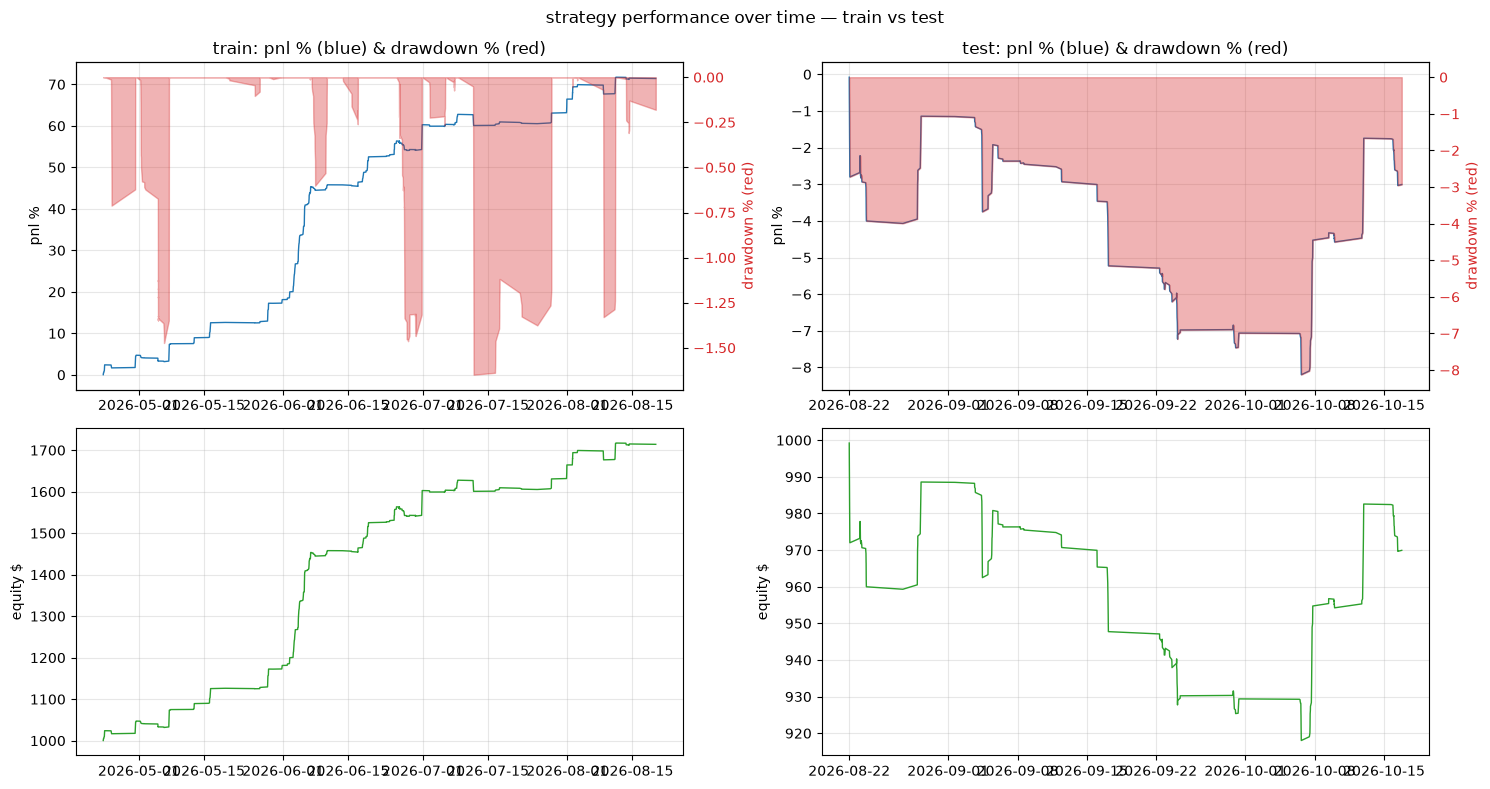


[train] rows 172,440
                  min          mean          max
symbol                                          
BTCUSDT   58169.81000  68393.198458  82761.29000
DOGEUSDT      0.06802      0.085962      0.11831
ETHUSDT    1513.11000   1938.163009   2423.05000
SOLUSDT      60.43000     78.219708     98.31000
XRPUSDT       0.98930      1.196610      1.54690
equity $ 1,000 -> 1,714.09 | total pnl $ 714.09
TRAIN: pnl   71.41%  dd  1.65%  wr  74.2%  trades  1685  pf   5.90

[test] rows 88,205
                  min          mean          max
symbol                                          
BTCUSDT   73107.36000  80983.761041  87278.42000
DOGEUSDT      0.07632      0.087918      0.10491
ETHUSDT    2325.35000   2534.764565   2804.69000
SOLUSDT      87.58000    107.695022    124.59000
XRPUSDT       1.25160      1.418253      1.67960
equity $ 1,000 -> 969.93 | total pnl $ -30.07
TEST : pnl   -3.01%  dd  8.20%  wr  32.5%  trades   726  pf   0.82


In [10]:
import json as _json
import matplotlib.pyplot as plt

si = 0                                    # which of the saved strategies to inspect
fname, s = saved[si]

doc = _json.load(open(fname))
print(f'strategy file: {fname}\n')

def curves(trades, initial_capital):
    dts = pd.to_datetime([t_['exit_dt'][:16] for t_ in trades])
    eq = np.array([t_['equity_after'] for t_ in trades], dtype=float)
    pnl_pct = (eq / initial_capital - 1.0) * 100.0
    peak = np.maximum.accumulate(eq)
    dd_pct = (peak - eq) / peak * 100.0
    return dts, eq, pnl_pct, dd_pct

fig, axes = plt.subplots(2, 2, figsize=(15, 8))
for col, (split_name, key) in enumerate((('train', 'trades'), ('test', 'trades_test'))):
    d = doc.get(key, [])
    ax, ax2 = axes[0, col], axes[1, col]
    x = pnl_pct = dd_pct = None
    if d:
        eq0 = d[0]['equity_after'] - d[0]['pnl_usd']
        x, eq, pnl_pct, dd_pct = curves(d, eq0)
        axr = ax.twinx()
        ax.plot(x, pnl_pct, color='tab:blue', lw=1)
        axr.fill_between(x, 0, -dd_pct, color='tab:red', alpha=.35)
        axr.set_ylabel('drawdown % (red)', color='tab:red')
        for lbl in axr.get_yticklabels(): lbl.set_color('tab:red')
        ax2.plot(x, eq, color='tab:green', lw=1)
        ax2.set_ylabel('equity $'); ax2.grid(alpha=.3)
        print(f"{split_name.upper():5}: pnl final {pnl_pct[-1]:+7.2f}% | max dd {dd_pct.max():5.2f}% | "
              f"final equity $ {eq[-1]:,.2f} | trades {len(d)}")
    ax.set_title(f'{split_name}: pnl % (blue) & drawdown % (red)')
    ax.set_ylabel('pnl %'); ax.grid(alpha=.3)
plt.suptitle('strategy performance over time — train vs test')
plt.tight_layout(); plt.show()

for split_name, frame in (('train', train), ('test', test)):
    print(f"\n[{split_name}] rows {len(frame):,}")
    print(frame.groupby('symbol')['candle_close'].agg(['min', 'mean', 'max']).to_string())
    d = doc.get('trades' if split_name == 'train' else 'trades_test', [])
    t = s[split_name]
    if d:
        eq0, eqn = d[0]['equity_after'] - d[0]['pnl_usd'], d[-1]['equity_after']
        print(f"equity $ {eq0:,.0f} -> {eqn:,.2f} | total pnl $ {eqn - eq0:,.2f}")
    print(f"{split_name.upper():5}: pnl {t['pnl']:7.2f}%  dd {t['dd']:5.2f}%  wr {t['wr']:5.1f}%  trades {t['trades']:5d}  pf {t['pf']:6.2f}")
